In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'jax', 'jaxlib', 'flax', 'optax', 'orbax-checkpoint', 'tensorflow', 'protobuf', 'ml-dtypes']
imports = {'pillow': 'PIL', 'orbax-checkpoint': 'orbax', 'protobuf': 'google.protobuf', 'ml-dtypes': 'ml_dtypes'}
pinned = {'jax': ('0.12.0.1', 'jax==0.12.0.1', 'jax[cuda12]==0.12.0.1', 'exact'), 'jaxlib': ('0.12.0.1', 'jaxlib==0.12.0.1', 'jaxlib==0.12.0.1', 'exact'), 'flax': ('0.12.12', 'flax==0.12.12', 'flax==0.12.12', 'exact'), 'optax': ('0.2.8', 'optax==0.2.8', 'optax==0.2.8', 'exact'), 'orbax-checkpoint': ('0.12.0', 'orbax-checkpoint==0.12.0', 'orbax-checkpoint==0.12.0', 'exact')}
fallbacks = {'tensorflow': 'tensorflow==2.21.0', 'protobuf': 'protobuf==7.34.1', 'ml-dtypes': 'ml-dtypes==0.5.4'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'jax' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'jax' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        if requirement is None:  # a GPU-only package on a CPU runtime
            continue
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, cpu_requirement, _, match) in pinned.items():
    if not gpu and cpu_requirement is None:
        continue
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "46d487bb9b699b97c7c5fc5edd866e4d2ad7919b"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/46d487bb9b699b97c7c5fc5edd866e4d2ad7919b/d2l"
for name in ('__init__.py', 'jax.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Adversarial Objectives and Divergences

Most GAN implementations offer several interchangeable training objectives: non-saturating logistic loss, least squares (LSGAN), hinge loss, and Wasserstein loss. that section analyzed the logistic objective, showing that its optimal discriminator recovers the log density ratio $\lambda(x) = \log(p(x)/q(x))$ and its minimax value is the Jensen–Shannon divergence—a quantity that saturates once the supports of $p$ and $q$ cease to overlap. What divergences do the other objectives measure? And when generated samples lie far from the data, does a vanishing gradient stem from the loss function, the critic architecture, or the underlying divergence?

Every objective in this family modifies either the scoring functions applied to the critic's outputs or the function class $\mathcal{T}$ over which the critic optimizes. Unconstrained critics paired with classification losses evaluate $f$-divergences, which depend only on the pointwise density ratio $p(x)/q(x)$. Constraining the critic to a smooth function class with linear payoffs instead yields *integral probability metrics* (IPMs), such as Maximum Mean Discrepancy (MMD) and the Wasserstein-1 distance ($W_1$), which remain sensitive to spatial distances even when supports are disjoint. Below, we derive both families and compare their behavior on separated 1D Gaussians and a 2D Gaussian mixture.

In [ ]:
# Deterministic GPU kernels; JAX reads XLA_FLAGS once, before the imports
import os
os.environ['XLA_FLAGS'] = (os.environ.get('XLA_FLAGS', '') +
                           ' --xla_gpu_deterministic_ops=true').strip()

In [1]:
import math
import numpy as np
import jax
from jax import numpy as jnp
from flax import nnx
import optax
from d2l import jax as d2l

In [2]:
from jax.nn import relu, softplus

## A General Template

In that section, the critic received $\log \sigma(D(x))$ on real samples $x \sim p$ and $\log \sigma(-D(x'))$ on generated samples $x' \sim q$. Replacing these log-likelihood terms with general payoff functions $\ell_p$ and $\ell_q$ over a critic class $\mathcal{T}$ yields the general adversarial discrepancy:

$$
\begin{aligned}
d(p, q) &= \sup_{T \in \mathcal{T}} \Big\{ \mathbb{E}_{x \sim p}\big[\ell_p(T(x))\big] \\
&\qquad\qquad + \mathbb{E}_{x' \sim q}\big[\ell_q(T(x'))\big] \Big\}.
\end{aligned}
$$

Setting $\ell_p(t) = \log \sigma(t)$ and $\ell_q(t) = \log \sigma(-t)$ with $\mathcal{T}$ unconstrained recovers $2\,\mathrm{JS}(p, q) - 2\log 2$. Throughout this section, the critic maximizes the sum of expected payoffs (equivalently, minimizes the negative payoffs, which we refer to as the critic loss).

the table organizes the chapter's objectives along two axes: whether the critic scores individual samples or real–generated pairs, and whether the critic class $\mathcal{T}$ is unconstrained or regularized.

<!-- tbl-caption:Taxonomy of adversarial objectives by critic input and function-class constraint. -->

| | unconstrained critic | constrained or penalized critic |
|:---|:---|:---|
| **single-sample critic** | classification losses (logistic, least squares, hinge) $\to$ $f$-divergences of $p/q$ | linear payoffs on an RKHS ball (MMD) or Lipschitz ball ($W_1$); hinge loss with spectral normalization |
| **pairwise critic** | relativistic pairing loss (RpGAN, that section) | pairing loss with zero-centered gradient penalties $R_1 + R_2$ (R3GAN, that section, that section) |

Note that for any fixed critic $T$, the expectation inside the equation is linear in the distribution $q$. Because the supremum of a family of linear functionals is convex, $d(p, q)$ is always convex in the probability measure $q$ for fixed $p$. However, because the set of distributions $\{q_\theta\}$ parameterized by a neural network $G_\theta$ is not convex, convexity in distribution space does not imply convexity in the generator parameters $\theta$ (Exercise 1).

## Classification Losses and $f$-Divergences

### A Two-Outcome Example

Consider a binary outcome space (heads and tails) with data distribution $p = (\tfrac34, \tfrac14)$ and generator distribution $q = (\tfrac14, \tfrac34)$, sampled with equal prior probability $\tfrac12$. Given an outcome, the Bayes posterior probability that it came from $p$ is $\eta = p/(p + q)$, which equals $\tfrac34$ for heads and $\tfrac14$ for tails. A blind prediction ($D = 0$) predicts $\tfrac12$ regardless of the outcome. The reduction in expected loss from observing the outcome depends on the classification loss:

- *Log loss*: the optimal prediction $\eta$ achieves binary entropy $H_b(\tfrac34) = 0.562$ nats versus $\log 2 = 0.693$ nats for a blind guess, saving $0.131\text{ nats} = \mathrm{JS}(p, q)$.
- *Squared error* on probabilities: predicting $\eta$ achieves expected loss $\tfrac34 \cdot \tfrac14 = \tfrac{3}{16}$ versus $\tfrac14$ for predicting $\tfrac12$, saving $\tfrac{1}{16}$.
- *Hinge loss* on a score $t$: the optimal scores $t = +1$ (heads) and $t = -1$ (tails) achieve expected loss $2 \cdot \tfrac14 = \tfrac12$ versus $1$ at $t = 0$, saving $\tfrac12 = \mathrm{TV}(p, q) = \tfrac12 \sum |p - q|$.

Each loss assigns a different nonnegative divergence to the same pair $(p, q)$ based on the same posterior $\eta$. We now show that every margin-based classification loss defines an $f$-divergence.

### The Bayes-Risk Gap

Symmetric classification losses apply a single margin payoff $\ell$ to $D(x)$ on real samples and to $-D(x')$ on generated samples ($\ell_p(t) = \ell(t)$, $\ell_q(t) = \ell(-t)$):

$$
V_\ell(D) \;=\; \mathbb{E}_{x \sim p}\big[\ell(D(x))\big] + \mathbb{E}_{x' \sim q}\big[\ell(-D(x'))\big].
$$

Here the signed score $t$ ($+D(x)$ on real data, $-D(x')$ on generated data) is the classification *margin*. At each point $x$, $p(x)\ell(t) + q(x)\ell(-t) = 2m(x)\big[\eta(x)\ell(t) + (1 - \eta(x))\ell(-t)\big]$, where $m = (p+q)/2$ and $\eta(x) = p(x)/(p(x)+q(x))$. The minimum pointwise expected loss at posterior $\eta$ is the *conditional Bayes risk*:

$$
L(\eta) \;=\; \inf_{t} \Big\{ \eta \, \big({-\ell(t)}\big) + (1 - \eta)\, \big({-\ell(-t)}\big) \Big\}.
$$

As an infimum of affine functions of $\eta$, $L(\eta)$ is concave on $[0, 1]$. A constant critic ($t = 0$) achieves risk $L(\tfrac12)$. The reduction in risk from observing $x$ is the *Bayes-risk gap*:

$$
\Delta_\ell(p, q) \;=\; L(\tfrac12) - \mathbb{E}_{x \sim m}\big[L(\eta(x))\big],
$$

which determines the optimal value $\sup_D V_\ell(D) = 2\Delta_\ell(p, q) - 2L(\tfrac12)$. By Jensen's inequality and $\mathbb{E}_m[\eta] = \tfrac12$, $\Delta_\ell(p, q) \geq 0$.

### Bayes-Risk Gaps as $f$-Divergences

Recall from that section that an $f$-divergence averages a convex function $f$ (with $f(1) = 0$) of the density ratio $\rho(x) = p(x)/q(x)$ under $q$: $D_f(p \,\|\, q) = \mathbb{E}_{x \sim q}[f(\rho(x))]$.

**Proposition.** *If the conditional Bayes risk $L$ is finite on $[0, 1]$, then*

$$
\begin{aligned}
\Delta_\ell(p, q) &= D_f(p \,\|\, q) \\
\textrm{with}\quad f(u) &= L(\tfrac12) - \frac{u+1}{2}\, L\!\left(\frac{u}{u+1}\right),
\end{aligned}
$$

*where $f$ is convex on $[0, \infty)$ with $f(1) = 0$.*

**Proof.** Substituting $u = \rho = p/q$ gives $m = q\,(u+1)/2$ and $\eta = u/(u+1)$, so

$$
\mathbb{E}_{x \sim m}\big[L(\eta(x))\big] = \int q \, \frac{u+1}{2}\, L\!\left(\frac{u}{u+1}\right),
$$

and moving $L(\tfrac12) = \int q\, L(\tfrac12)$ inside the integral yields $\Delta_\ell(p, q) = \mathbb{E}_q[f(\rho)]$. Writing the concave function $L(v) = \inf_j \{\alpha_j v + \beta_j\}$ as the lower envelope of its tangent lines shows that $(u+1)L(u/(u+1)) = \inf_j \{\alpha_j u + \beta_j(u+1)\}$ is concave in $u$; hence $f(u)$ is convex, and $f(1) = L(\tfrac12) - L(\tfrac12) = 0$. $\blacksquare$

Thus, every symmetric classification loss with an unconstrained critic evaluates an $f$-divergence, and its optimal critic $D^\star(x)$ is a monotone *link function* of the log density ratio $\lambda(x) = \log(p(x)/q(x))$.

### Divergences of Common Classification Losses

the table summarizes four standard classification losses, their conditional Bayes risks $L(\eta)$, Bayes-risk gaps $\Delta_\ell(p, q)$, optimal critic links $D^\star(\lambda)$, and the practical generator losses used with them.

<!-- tbl-caption:Classification losses with an unconstrained critic: margin loss $-\ell(t)$, Bayes risk $L(\eta)$, Bayes-risk gap $\Delta_\ell(p, q)$, optimal critic link $D^\star(\lambda)$, and practical generator loss on $D = D(x')$. -->

| loss | margin loss $-\ell(t)$ | Bayes risk $L(\eta)$ | gap $\Delta_\ell(p,q)$ | optimal critic link | generator loss |
|:---|:---|:---|:---|:---|:---|
| logistic | $\log(1 + e^{-t})$ | $H_b(\eta)$ | $\mathrm{JS}(p,q)$ | $\lambda$ | $-\log \sigma(D)$ |
| least squares (LSGAN) | $\tfrac14 (1 - t)^2$, $t = 2D - 1$ | $\eta(1-\eta)$ | $\tfrac{1}{8}\int \frac{(p-q)^2}{p+q}$ | $\sigma(\lambda)$ | $\tfrac12 (D - 1)^2$ |
| squared hinge | $\max(0, 1 - t)^2$ | $4\eta(1-\eta)$ | $\tfrac{1}{2}\int \frac{(p-q)^2}{p+q}$ | $\tanh(\lambda/2)$ | $-D$ |
| hinge | $\max(0, 1 - t)$ | $2\min(\eta, 1-\eta)$ | $\mathrm{TV}(p,q)$ | $\operatorname{sign} \lambda$ | $-D$ |

In LSGAN [@Mao.Li.Xie.ea.2017], the critic regresses onto targets $1$ (real) and $0$ (fake), which under $t = 2D - 1$ corresponds to squared margin loss $\tfrac14(1 - t)^2$ and evaluates one-quarter of the Vincze–Le Cam divergence $\chi^2(p \,\|\, m) = \tfrac12 \int (p-q)^2/(p+q)$. The hinge loss [@Lim.Ye.2017] evaluates total variation $\mathrm{TV}(p, q) = \tfrac12 \int |p - q|$, and its optimal critic outputs $\operatorname{sign} \lambda$ (with any value in $[-1, 1]$ optimal at $\eta = \tfrac12$). The squared hinge loss shares the hinge margin and generator objective $-D(x')$, but its smooth link $\tanh(\lambda/2)$ preserves the magnitude of $\lambda$. In practice, each loss uses a non-saturating generator objective (final column) that shares the equilibrium $q = p$.

### The Fenchel–Young Variational Bound ($f$-GAN)

Because the equation applies the same payoff to $D$ and $-D$, its Bayes risk satisfies $L(\eta) = L(1 - \eta)$, so every classification gap $\Delta_\ell(p, q)$ is symmetric in $p$ and $q$ and bounded above by $L(\tfrac12)$ (Exercise 5). Reaching asymmetric or unbounded $f$-divergences such as the forward KL divergence $D_{\textrm{KL}}(p \,\|\, q)$ requires asymmetric payoffs $\ell_p \neq \ell_q$.

Let $f^*(t) = \sup_u \{ut - f(u)\}$ be the *convex conjugate* of a convex divergence function $f$. By the Fenchel–Young inequality, $f(u) \geq ut - f^*(t)$ for all $u, t$, with equality when $t = f'(u)$. Setting $u = \rho(x) = p(x)/q(x)$ and $t = T(x)$ and taking the expectation under $q$ (using $\mathbb{E}_q[\rho\, T] = \mathbb{E}_p[T]$) yields the variational lower bound of $f$-GAN [@Nowozin.Cseke.Tomioka.2016] (that section):

$$
D_f(p \,\|\, q) \;\geq\; \mathbb{E}_{x \sim p}\big[T(x)\big] - \mathbb{E}_{x' \sim q}\big[f^*(T(x'))\big].
$$

This matches our template the equation with $\ell_p(t) = t$ and $\ell_q(t) = -f^*(t)$, and is tight at the optimal critic $T^\star(x) = f'(\rho(x))$ (Exercise 2). For the forward KL divergence, $f(u) = u \log u$ has conjugate $f^*(t) = e^{t-1}$ and optimal critic $T^\star(x) = 1 + \log \rho(x) = 1 + \lambda(x)$.

### Verifying Critic Link Functions Empirically

We now verify that critics trained under the logistic, least-squares, hinge, and forward-KL objectives learn their respective theoretical link functions of $\lambda(x)$: $\lambda$, $\sigma(\lambda)$, $\operatorname{sign} \lambda$, and $1 + \lambda$. We define $p$ as a uniform mixture of three 2D Gaussians and construct a perturbed 3-component mixture $q$ so that $\lambda(x)$ is known analytically everywhere.

In [ ]:

mu_p = np.array([[0.0, 2.4], [-2.1, -1.2], [2.1, -1.2]])     # data
A_p = np.stack([0.7 * np.eye(2)] * 3)

mu_q = np.array([[0.2, 2.6], [-2.3, -1.0], [2.0, -1.3]])     # hand-set q
A_q = np.stack([np.diag([0.8, 0.55]), np.diag([0.5, 0.6]),
                np.array([[0.65, 0.2], [-0.1, 0.7]])])


def mixture_logpdf(x, mus, As):
    """Log density of the uniform mixture of Gaussians N(mu_k, A_k^T A_k)."""
    comps = []
    for mu, A in zip(mus, As):
        Sigma, diff = A.T @ A, x - mu
        sol = np.linalg.solve(Sigma, diff.T).T
        comps.append(-0.5 * ((diff * sol).sum(1)
                             + np.linalg.slogdet(2 * np.pi * Sigma)[1]))
    return np.logaddexp.reduce(np.stack(comps) - np.log(len(mus)), axis=0)


def sample_mixture(n, mus, As, rng):
    """n draws from the uniform mixture of Gaussians mu_k + z A_k."""
    k = rng.integers(0, len(mus), n)
    z = rng.standard_normal((n, 2))
    return np.einsum('ni,nij->nj', z, As[k]) + mus[k]

On a fixed grid, quadrature gives $\mathrm{JS}(p, q)$ for any mixture $q$ of this form. Later in the section the same function scores a trained generator after every step.

In [ ]:

grid_1d = np.linspace(-7.0, 7.0, 281)
grid_2d = np.stack([g.ravel() for g in np.meshgrid(grid_1d, grid_1d)], axis=1)
cell_area = (grid_1d[1] - grid_1d[0]) ** 2


def js_mixtures(mus_q, As_q, mus_p=mu_p, As_p=A_p):
    """JS(p, q) between two known mixtures, p the data by default, by
    quadrature on grid_2d."""
    logp = mixture_logpdf(grid_2d, mus_p, As_p)
    logq = mixture_logpdf(grid_2d, mus_q, As_q)
    p, q = np.exp(logp), np.exp(logq)
    logm = np.log(np.maximum((p + q) / 2, 1e-300))
    return 0.5 * (p * (logp - logm) + q * (logq - logm)).sum() * cell_area

print(f'JS(p, q) for the hand-set q: {js_mixtures(mu_q, A_q):.3f} nats')

The hand-set $q$ is a few hundredths of a nat from the data, a mismatch of the size a generator meets late in training. The critic is a small leaky-ReLU network with two hidden layers of 64 units.

In [ ]:

def make_critic(rngs):
    """Leaky-ReLU MLP; nnx.Linear gives LeCun-normal weights, zero biases."""
    leaky = lambda x: nnx.leaky_relu(x, 0.2)
    return nnx.Sequential(nnx.Linear(2, 64, rngs=rngs), leaky,
                          nnx.Linear(64, 64, rngs=rngs), leaky,
                          nnx.Linear(64, 1, rngs=rngs))

Each loss is stored as a pair, the critic's loss and the generator's loss of the table, both written on the critic's scores `r` of a real batch and `f` of a generated one.

In [ ]:
losses = {  # name: (critic loss, generator loss), both on the scores r, f
    'logistic': (lambda r, f: (softplus(-r) + softplus(f)).mean(),
                 lambda r, f: softplus(-f).mean()),
    'least squares': (lambda r, f: ((r - 1) ** 2 + f ** 2).mean() / 2,
                      lambda r, f: ((f - 1) ** 2).mean() / 2),
    'hinge': (lambda r, f: (relu(1 - r) + relu(1 + f)).mean(),
              lambda r, f: -f.mean()),
    'squared hinge': (lambda r, f: (relu(1 - r) ** 2 + relu(1 + f) ** 2).mean(),
                      lambda r, f: -f.mean()),
}

A link describes the best response to a fixed $q$, so we train a fresh critic against the hand-set $q$ under three of the losses, and a fourth to maximize the forward-KL bound $\mathbb{E}_p[T] - \mathbb{E}_q[e^{T-1}]$.

In [7]:
@nnx.jit(static_argnums=0)
def best_response_step(critic_loss, D, opt, X, Y):
    opt.update(D, nnx.grad(lambda D_: critic_loss(D_(X), D_(Y)))(D))

def best_response(critic_loss, seed=0, steps=3000, batch=512, lr=1e-3):
    """Fresh critic trained against the fixed q, as a NumPy function."""
    rng = np.random.default_rng(seed)
    D = make_critic(nnx.Rngs(seed))
    opt = nnx.Optimizer(D, optax.adam(lr), wrt=nnx.Param)
    for _ in range(steps):
        X = jnp.asarray(sample_mixture(batch, mu_p, A_p, rng), jnp.float32)
        Y = jnp.asarray(sample_mixture(batch, mu_q, A_q, rng), jnp.float32)
        best_response_step(critic_loss, D, opt, X, Y)
    return lambda x: np.asarray(D(jnp.asarray(x, jnp.float32))).squeeze(-1)

kl_dual = lambda r, f: -(r.mean() - jnp.exp(f - 1).mean())
critics = {name: best_response(losses[name][0])
           for name in ('logistic', 'least squares', 'hinge')}
critics['forward KL'] = best_response(kl_dual)

We evaluate each trained critic at 300 points from $p$ and 300 from $q$, plotting its output against the true log density ratio $\lambda(x)$ alongside the theoretical link function (dashed curve).

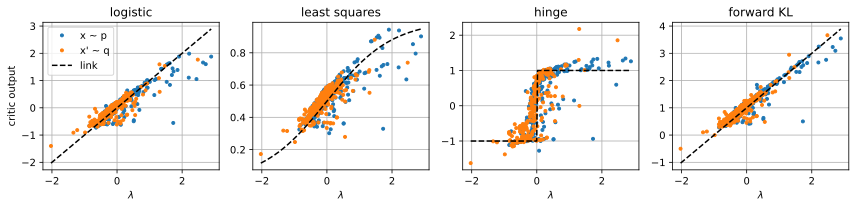

In [8]:
rng = np.random.default_rng(7)
pts = np.concatenate([sample_mixture(300, mu_p, A_p, rng),
                      sample_mixture(300, mu_q, A_q, rng)])
lam = mixture_logpdf(pts, mu_p, A_p) - mixture_logpdf(pts, mu_q, A_q)
lam_line = np.linspace(lam.min(), lam.max(), 200)
links = {'logistic': lambda l: l, 'least squares': lambda l: 1 / (1 + np.exp(-l)),
         'hinge': np.sign, 'forward KL': lambda l: 1 + l}
fig, axes = d2l.plt.subplots(1, 4, figsize=(12, 3))
for ax, (name, link) in zip(axes, links.items()):
    out = critics[name](pts)
    d2l.plot([lam[:300], lam[300:], lam_line],
             [out[:300], out[300:], link(lam_line)], xlabel=r'$\lambda$',
             fmts=('.', '.', 'k--'), axes=ax,
             legend=['x ~ p', "x' ~ q", 'link'] if name == 'logistic' else None)
    ax.set_title(name)
axes[0].set_ylabel('critic output')
fig.tight_layout()

All four networks track their predicted theoretical links of $\lambda(x)$: the identity $\lambda$, the sigmoid $\sigma(\lambda)$, the step function $\operatorname{sign} \lambda$, and the shifted identity $1 + \lambda$. Note the wider scatter of the hinge critic near $\lambda = 0$, where any output in $[-1, 1]$ achieves the minimum conditional risk.

## Integral Probability Metrics

Whereas $f$-divergences pair an unconstrained critic with nonlinear payoffs, *integral probability metrics* (IPMs) use linear payoffs $\ell_p(t) = t$ and $\ell_q(t) = -t$ while restricting the critic to a symmetric function class $\mathcal{F}$ (that section):

$$
d_{\mathcal{F}}(p, q) \;=\; \sup_{T \in \mathcal{F}} \Big\{ \mathbb{E}_{x \sim p}\big[T(x)\big] - \mathbb{E}_{x' \sim q}\big[T(x')\big] \Big\}.
$$

Without a constraint on $\mathcal{F}$, scaling $T$ by an arbitrary positive constant would send the difference of expectations to $+\infty$ whenever $p \neq q$. When $\mathcal{F}$ consists of smooth functions, $d_{\mathcal{F}}(p, q)$ depends on the spatial geometry of $\mathcal{X}$ rather than just the pointwise ratio $p(x)/q(x)$.

### Maximum Mean Discrepancy (MMD)

Given a positive-definite kernel $k(x, x')$, such as the Gaussian RBF kernel $k(x, x') = \exp(-\|x - x'\|^2/(2s^2))$ with bandwidth $s$, choosing $\mathcal{F}$ to be the unit ball of the reproducing kernel Hilbert space (RKHS) associated with $k$ yields the *Maximum Mean Discrepancy* [@Gretton.Borgwardt.Rasch.ea.2012] (that section), whose squared value has a closed form in terms of pairwise kernel expectations:

$$
\begin{aligned}
\mathrm{MMD}^2(p, q)
&= \mathbb{E}_{x, \tilde x \sim p}\big[k(x, \tilde x)\big] + \mathbb{E}_{x', \tilde x' \sim q}\big[k(x', \tilde x')\big] \\
&\quad - 2\, \mathbb{E}_{x \sim p,\, x' \sim q}\big[k(x, x')\big].
\end{aligned}
$$

The optimal test function (up to scaling) is the *witness function* $w(x) = \mathbb{E}_{\tilde x \sim p}[k(x, \tilde x)] - \mathbb{E}_{\tilde x' \sim q}[k(x, \tilde x')]$, which measures the difference between a point's average similarity to $p$ and its average similarity to $q$. Because the equation requires no critic network, a generator can minimize the unbiased finite-sample estimator `mmd2_unbiased` directly (also used in that section to compute KID).

In [9]:

def mmd2_unbiased(K_pp, K_qq, K_pq):
    """Unbiased MMD^2 from the kernel matrices within p, within q, and
    across; the diagonals (a point with itself) are left out."""
    m, n = len(K_pp), len(K_qq)
    return ((K_pp.sum() - K_pp.diagonal().sum()) / (m * (m - 1))
            + (K_qq.sum() - K_qq.diagonal().sum()) / (n * (n - 1))
            - 2 * K_pq.mean())

### Wasserstein-1 Distance ($W_1$)

Choosing $\mathcal{F}$ to be the class of *1-Lipschitz* functions ($|T(x) - T(y)| \leq \|x - y\|$ for all $x, y$) yields the *Wasserstein-1* (or *Earth Mover's*) distance via Kantorovich–Rubinstein duality (that section):

$$
W_1(p, q) \;=\; \inf_{\pi \in \Pi(p, q)} \mathbb{E}_{(x, x') \sim \pi}\big[\|x - x'\|\big],
$$

where $\Pi(p, q)$ is the set of joint transport plans with marginals $p$ and $q$. An optimal 1-Lipschitz critic (a *Kantorovich potential*) has unit gradient norm along the optimal transport rays from $q$ to $p$. In 1D, $W_1(p, q) = \int_{-\infty}^\infty |F_p(t) - F_q(t)|\,dt$, so shifting a distribution by $\mu$ gives $W_1(p, q) = |\mu|$ with constant unit slope at any separation.

In higher dimensions, Wasserstein GANs (WGANs) approximate the 1-Lipschitz constraint on a neural network critic $T$ via three main mechanisms:

1. *Weight clipping* [@Arjovsky.Chintala.Bottou.2017] clamps weights to $[-c, c]$, enforcing $\kappa$-Lipschitzness for an architecture-dependent constant $\kappa$ at the cost of restricting capacity.
2. *Gradient penalty* (WGAN-GP) [@Gulrajani.Ahmed.Arjovsky.ea.2017] adds $\gamma\,\mathbb{E}[(\|\nabla_x T(\tilde x)\| - 1)^2]$ at random interpolants $\tilde x = u x + (1-u)x'$ between real and generated samples.
3. *Spectral normalization* [@Miyato.Kataoka.Koyama.ea.2018] normalizes each weight matrix by its largest singular value $\sigma_{\max}(W)$, bounding the Lipschitz constant of every linear layer by $1$.

Notice that the hinge loss bridges the two families: when $|D(x)| \leq 1$, its payoffs are linear, so an unconstrained hinge critic corresponds to the IPM over functions bounded by $|D(x)| \leq 1$ (evaluating $2\,\mathrm{TV}(p, q) - 2$). Combining the hinge loss with spectral normalization (making $D$ both bounded and $\kappa$-Lipschitz, as in SAGAN and BigGAN) yields a critic whose value grows linearly like $\kappa\,W_1$ up to separation $2/\kappa$ before saturating.

### Sample Complexity in High Dimensions

Fixed-kernel MMD and empirical $W_1$ differ sharply in sample complexity: the unbiased $\mathrm{MMD}^2$ estimator converges at the dimension-independent rate $O(n^{-1/2})$ [@Gretton.Borgwardt.Rasch.ea.2012] (although the quantity being estimated, the $\mathrm{MMD}^2$ of a given shift under a fixed kernel, can itself shrink as the dimension grows [@Ramdas.Reddi.Poczos.ea.2015]), whereas the plug-in empirical $W_1$ distance in dimension $d_x > 2$ suffers from the curse of dimensionality at rate $O(n^{-1/d_x})$ [@Weed.Bach.2019]. Meanwhile, variational $f$-divergence estimators can suffer from high variance when $\rho = p/q$ is large: for example, in the forward-KL dual bound, the variance of $e^{T^\star(x') - 1} = \rho(x')$ under $q$ equals $\chi^2(p \,\|\, q)$, which can diverge even when $D_{\textrm{KL}}(p \,\|\, q) < \infty$ (Exercise 4).

## Gradients Far from and Near the Data

### Divergence Slope versus Separation

To see how the population divergences behave as two distributions separate, consider $p = \mathcal{N}(0, 1)$ and $q = \mathcal{N}(\mu, 1)$ as a function of the separation $\mu > 0$. Here $W_1(p, q) = \mu$ has constant derivative $1$, $\mathrm{JS}(p, q)$ can be integrated numerically, and $\mathrm{MMD}^2(p, q)$ under the Gaussian RBF kernel of bandwidth $s$ has the exact Gaussian integral:

$$
\mathrm{MMD}^2(p, q) \;=\; \frac{2s}{\sqrt{s^2 + 2}} \left( 1 - \exp\!\left( -\frac{\mu^2}{2(s^2 + 2)} \right) \right),
$$

whose derivative with respect to $\mu$ peaks at $\mu = \sqrt{s^2 + 2}$ ($\approx 4.2$ for $s = 4$) before decaying as $e^{-\mu^2/(2(s^2+2))}$.

In [ ]:
xs = np.linspace(-10.0, 30.0, 8001)           # fixed quadrature grid

def normal_pdf(x, mu, sigma=1.0):
    return np.exp(-(x - mu) ** 2 / (2 * sigma ** 2)) / np.sqrt(
        2 * np.pi * sigma ** 2)

def js_gap(p, q):
    """log 2 - JS(p, q) on xs, accurate even when tiny: the integral of
    (p log(1 + q/p) + q log(1 + p/q)) / 2, with log(1 + e^a) computed as
    logaddexp(0, a)."""
    a = np.log(q) - np.log(p)
    return 0.5 * np.trapezoid(p * np.logaddexp(0, a) + q * np.logaddexp(0, -a),
                              xs)

def js_1d(p, q):
    return np.log(2) - js_gap(p, q)

s = 4.0                                        # RBF kernel bandwidth
mus = np.linspace(0.1, 20.0, 200)              # separations mu
gaps = np.array([js_gap(normal_pdf(xs, 0.0), normal_pdf(xs, mu))
                 for mu in mus])
mmd2 = 2 * s / np.sqrt(s ** 2 + 2) * (1 - np.exp(-mus ** 2
                                                 / (2 * (s ** 2 + 2))))
slopes = [-np.gradient(gaps, mus), np.gradient(mmd2, mus),
          np.ones_like(mus)]                   # W1 = |mu| has slope one
for mu in (1.0, 7.0, 20.0):
    js = js_1d(normal_pdf(xs, 0.0), normal_pdf(xs, mu))
    print(f'mu = {mu:2.0f}: JS slope {np.interp(mu, mus, slopes[0]):.4g}, '
          f'JS / log 2 = {js / np.log(2):.4f}, '
          f'MMD^2 slope {np.interp(mu, mus, slopes[1]):.4g}')
peak = slopes[1].argmax()
print(f'MMD^2 slope peaks at mu = {mus[peak]:.1f} with {slopes[1][peak]:.3f}')
d2l.plot(mus, slopes, xlabel=r'separation $\mu$', ylabel='slope',
         legend=['JS', 'MMD$^2$', '$W_1$'], yscale='log', figsize=(5, 3))

As shown in the plot and the figure, the derivative of $\mathrm{JS}(p, q)$ drops by over two orders of magnitude by $\mu = 7$ ($0.0013$ vs. $0.20$ at $\mu = 1$) and reaches $1.5 \times 10^{-22}$ at $\mu = 20$. By contrast, $W_1$ maintains unit slope at every distance, and $\mathrm{MMD}^2$ maintains a strong gradient up to separations on the order of the kernel bandwidth $s$.

![Optimal critics when $p$ (blue) and $q$ (orange) have disjoint supports. Left: the JS optimal critic $\log(p/q)$ takes values $+\infty$ on $\operatorname{supp}(p)$ and $-\infty$ on $\operatorname{supp}(q)$, with zero slope on both. Middle: the $W_1$ Kantorovich potential is a linear ramp of unit slope. Right: the MMD witness $\mathbb{E}_p[k(x, \cdot)] - \mathbb{E}_q[k(x, \cdot)]$ is a smooth difference of kernel bumps whose tail slopes toward $p$.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-gan-critics-separated.svg)

### Trained Critics from a Separated Start

Theoretical divergence curves assume an optimal critic over all measurable functions. In practice, the critic is a finite neural network trained for a few steps per generator update. To test how trained critics behave from a distant initialization, we fit a 1D location generator $q_\theta = \mathcal{N}(\theta, 1)$ ($x' = \theta + z$) starting at $\theta_0 = 6$ to $p = \mathcal{N}(0, 1)$, updating $\theta$ by vanilla SGD (so step sizes directly reflect gradient magnitudes) against a 2-hidden-layer ReLU critic updated 5 times per generator step.

In [ ]:
def mmd2_loss(x, y, bandwidths=(0.5, 1.0, 2.0)):
    """Unbiased MMD^2 under the sum of RBF kernels of the given bandwidths."""
    def kernel(a, b):
        sq_dist = ((a[:, None] - b[None]) ** 2).sum(-1)
        return sum(jnp.exp(-sq_dist / (2 * s ** 2)) for s in bandwidths)
    return mmd2_unbiased(kernel(x, x), kernel(y, y), kernel(x, y))

def mmd2_median(x, y):
    """MMD^2 with one RBF kernel, its bandwidth the median pairwise distance
    of the pooled batch, held constant in the gradient."""
    xy = jnp.concatenate([x, y])
    dist = jnp.sqrt(((xy[:, None] - xy[None]) ** 2).sum(-1))
    return mmd2_loss(x, y, (jax.lax.stop_gradient(jnp.median(dist)),))


def gradient_penalty(D, X, fake, u, one_sided=False):
    """Mean (|D'(x)| - 1)^2 at the points u X + (1 - u) fake (inputs 1-D);
    one-sided, only slopes steeper than one pay: max(0, |D'(x)| - 1)^2."""
    grad = jax.grad(lambda x: D(x).sum())(u * X + (1 - u) * fake)
    excess = jnp.abs(grad) - 1
    return ((jnp.maximum(excess, 0) if one_sided else excess) ** 2).mean()

`train_shift` gives the critic five Adam steps for every generator step, which keeps it near its best response. The generator takes plain gradient steps with learning rate $0.01$: Adam would rescale every step to about its learning rate and hide the size of the gradient, which is what we want to see. The function records $\theta$ and the generator's gradient at every step. A positive `gp` adds the gradient penalty to the critic loss, and `one_sided=True` charges only slopes steeper than one, $\max(0, |T'| - 1)^2$; with `critic_loss` set to `None`, the generator minimizes `gen_loss` of the two batches.

In [ ]:

class Shift(nnx.Module):
    """The generator x' = theta + z."""
    def __init__(self, theta0):
        self.theta = nnx.Param(jnp.array(theta0))

    def __call__(self, z):
        return self.theta + z


@nnx.jit(static_argnums=(0, 1, 2, 3))
def shift_step(critic_loss, gen_loss, gp, one_sided, G, D, opt_G, opt_D, X, Z,
               U):
    """One critic step per row of U, then one generator step; returns the
    generator's gradient."""
    for i in range(len(U)):
        fake = G(Z[i])
        def d_loss(D_):
            loss = critic_loss(D_(X[i]), D_(fake))
            if gp:
                loss = loss + gp * gradient_penalty(D_, X[i], fake, U[i],
                                                    one_sided)
            return loss
        opt_D.update(D, nnx.grad(d_loss)(D))
    def g_loss(G_):
        fake = G_(Z[-1])
        return (gen_loss(X[-1], fake) if critic_loss is None
                else gen_loss(D(X[-1]), D(fake)))
    grad = nnx.grad(g_loss)(G)
    opt_G.update(G, grad)
    return grad.theta[...]


def train_shift(critic_loss, gen_loss, seed, gp=0.0, one_sided=False,
                theta0=6.0, steps=1500, n_critic=5, batch=256, lr_D=1e-2,
                lr_G=1e-2):
    """Fit x' = theta + z to N(0, 1) by plain gradient steps on theta; return
    theta0 and theta after every step, the gradient of every step, and the
    critic."""
    rng = np.random.default_rng(seed)
    G = Shift(theta0)
    D = d2l.make_mlp([1, 32, 32, 1], nnx.relu, rngs=nnx.Rngs(seed))
    opt_G = nnx.Optimizer(G, optax.sgd(lr_G), wrt=nnx.Param)
    opt_D = nnx.Optimizer(D, optax.adam(lr_D, 0.5, 0.9), wrt=nnx.Param)
    n = n_critic if critic_loss else 0
    thetas, grads = [theta0], []
    for _ in range(steps):
        X, Z = (jnp.asarray(rng.standard_normal((n + 1, batch, 1)),
                            jnp.float32) for _ in range(2))
        U = jnp.asarray(rng.uniform(size=(n, batch, 1)), jnp.float32)
        grad = shift_step(critic_loss, gen_loss, gp, one_sided, G, D, opt_G,
                          opt_D, X, Z, U)
        grads.append(grad)                      # device scalars,
        thetas.append(G.theta[...])             # converted once below
    return np.asarray(jnp.stack(thetas)), np.asarray(jnp.stack(grads)), D

We compare six configurations across three seeds each: saturating logistic, non-saturating logistic, hinge, WGAN-GP ($\gamma = 10$, two-sided penalty $(|T'| - 1)^2$), WGAN-GP with a one-sided penalty $\max(0, |T'| - 1)^2$, and median-bandwidth MMD. For each run we report the median generator gradient magnitude over the first 100 steps, the trajectory of $\theta$, the *arrival* step (first step where $|\theta| < 0.5$), and the *farthest* excursion $\max |\theta|$ after arrival.

In [ ]:
w1 = (lambda r, f: f.mean() - r.mean(), lambda r, f: -f.mean())
arms = {'logistic, sat.': (losses['logistic'][0],
                           lambda r, f: -softplus(f).mean(), {}),
        'logistic, NS': (*losses['logistic'], {}),
        'hinge': (*losses['hinge'], {}),
        'W1 + GP': (*w1, dict(gp=10.0)),
        'W1 + 1-sided GP': (*w1, dict(gp=10.0, one_sided=True)),
        'MMD, median': (None, mmd2_median, {})}
steps, w1_runs = (0, 100, 300, 1000, 1500), []  # (arm, seed, theta, critic)
print(f'{"":17s}|grad|   theta at steps {", ".join(map(str, steps))}'
      '  arrival  farthest')
for name, (critic_loss, gen_loss, kwargs) in arms.items():
    for seed in range(3):
        thetas, grads, D = train_shift(critic_loss, gen_loss, seed, **kwargs)
        if name.startswith('W1'):
            w1_runs.append((name, seed, thetas[-1], D))
        hit = np.flatnonzero(np.abs(thetas) < 0.5)  # arrival: hit[0]
        print(f'{name:16s}{seed}{np.median(np.abs(grads[:100])):7.3f} '
              + ''.join(f'{thetas[t]:7.2f}' for t in steps)
              + (f'{hit[0]:9d}{np.abs(thetas[hit[0]:]).max():10.2f}'
                 if len(hit) else '  not reached'))

The results clarify how practical neural critics differ from unconstrained theoretical optima:

- **Saturating vs. non-saturating logistic:** As in that section, the saturating generator gradient is tiny ($\sim 0.01$) and $\theta$ barely moves from $6.0$ to $5.76$, whereas the non-saturating generator receives a strong gradient ($\sim 3$) and reaches the target before step 400.
- **Hinge critic:** Although the theoretical optimal hinge critic $\operatorname{sign} \lambda$ has zero slope inside both clouds, a finite ReLU MLP interpolates smoothly across the gap with slope $1.1\text{--}1.7$, driving the generator to the target by steps $700\text{--}950$.
- **Median-bandwidth MMD:** Besides the saturating arm, this is the only one that has not arrived by step 1,500, where $\theta \approx 1.3$. The generator is slow here, but it has not stalled. Because the median heuristic keeps the bandwidth comparable to the separation, the gradient never vanishes. At $\sim 0.2$ it is about six times smaller than the slope of the $W_1$ critics in the next item, and plain gradient steps of size $0.01$ need correspondingly longer.
- **Two-sided vs. one-sided WGAN-GP:** Both $W_1$ arms pull the generator inward at slope $\approx 1.26$ (minimizing $-ad + 10(a-1)^2$ gives $a = 1 + d/20$) and arrive near step 500. After arrival, however, every two-sided `W1 + GP` run overshoots heavily (`farthest` $> 1$, up to $> 7$), whereas every one-sided run stays within $0.06$ of the origin. Why? Once $\theta$ crosses $0$, the critic must reverse its slope from negative to positive. Because the two-sided penalty $(|T'| - 1)^2$ penalizes a flat critic ($T' = 0$) by $\gamma$, it creates a potential barrier at zero slope that traps the critic on the old slope sign ($1 - d/20$) or causes all ReLU units to die, as confirmed by inspecting the critic slopes and active ReLU counts at step 1,500 below:

In [ ]:
def slope_and_units(D, x):
    """D'(x) and, per hidden layer, the number of ReLU units active at x."""
    def forward(x):
        h, active = x, []
        for layer in D.layers:
            h = layer(h)
            if not isinstance(layer, nnx.Linear):  # an activation
                active.append((h > 0).sum())
        return h.sum(), active
    slope, active = jax.grad(forward, has_aux=True)(jnp.array([[x]]))
    return float(slope.squeeze()), [int(a) for a in active]

print(f"{'':19s}theta D'(theta)  active    D'(0)  active"
      '  (of 32 units per layer)')
for name, seed, theta, D in w1_runs:
    (s_t, a_t), (s_0, a_0) = (slope_and_units(D, x) for x in (theta, 0.0))
    print(f'{name:16s}{seed}{theta:7.2f}{s_t:10.2f}{a_t[0]:5d}{a_t[1]:3d}'
          f'{s_0:9.2f}{a_0[0]:5d}{a_0[1]:3d}')

The one-sided penalty $\max(0, |T'| - 1)^2$ imposes no penalty when $|T'| \leq 1$, allowing the critic to pass freely through zero slope as $\theta$ reaches the data. that section analyzes zero-centered penalties ($R_1$ and $R_2$) that actively pull the critic slope to zero at equilibrium.

### Comparing Five Objectives on a 2D Gaussian Mixture

Next, we compare five objectives when the generator and data supports overlap: non-saturating logistic, least squares, hinge, squared hinge, and multi-bandwidth MMD ($s \in \{0.5, 1.0, 2.0\}$). The generator `MixtureGenerator` parameterizes a 3-component Gaussian mixture initialized with displaced means `mu_0` and narrower scales `A_0 = 0.4 * I` ($\mathrm{JS}(p, q_0) \approx 0.53$ nats).

In [ ]:

mu_0 = np.array([[1.0, -1.0], [-4.3, -2.0], [-1.0, 3.8]])  # off the modes
A_0 = np.stack([0.4 * np.eye(2)] * 3)      # below the data's scale of 0.7

print(f'JS(p, q) at the start: {js_mixtures(mu_0, A_0):.3f} nats')

The start is about half a nat from the data. The MMD arm minimizes the unbiased minibatch $\mathrm{MMD}^2$ under the sum of three RBF kernels with bandwidths $0.5$, $1$ and $2$, a kernel sensitive at several scales.

In [ ]:

class MixtureGenerator(nnx.Module):
    """x = mu_k + z A_k for a uniformly drawn component k."""
    def __init__(self, mu, A):
        self.mu = nnx.Param(jnp.asarray(mu, jnp.float32))
        self.A = nnx.Param(jnp.asarray(A, jnp.float32))

    def __call__(self, z, k):
        return jnp.einsum('ni,nij->nj', z, self.A[k]) + self.mu[k]

    def params_np(self):
        return np.asarray(self.mu[...]), np.asarray(self.A[...])

losses['MMD'] = (None, mmd2_loss)   # no critic: MMD^2 to the real batch

`train_toy` takes the two losses as arguments and alternates one critic step with one generator step. The MMD arm, stored with the critic loss `None`, takes only the generator step, on `mmd2_loss(X, fake)` instead of the critic's scores. Every 200 steps it records the exact $\mathrm{JS}(p, q_t)$.

In [ ]:

@nnx.jit(static_argnums=(0, 1))
def train_toy_step(critic_loss, gen_loss, G, D, opt_G, opt_D, X, z, k):
    """A critic step (unless critic_loss is None), then a generator step."""
    if critic_loss is not None:            # the generator is fixed here
        fake = G(z, k)
        opt_D.update(D, nnx.grad(lambda D_: critic_loss(D_(X), D_(fake)))(D))
    def g_loss(G_):
        fake = G_(z, k)
        return (gen_loss(X, fake) if critic_loss is None
                else gen_loss(D(X), D(fake)))
    opt_G.update(G, nnx.grad(g_loss)(G))


def train_toy(critic_loss, gen_loss, seed=0, steps=6000, batch=256, lr=1e-3):
    """Fit a MixtureGenerator from (mu_0, A_0) to the data mixture, one
    critic step per generator step. The losses act on the critic's scores of
    the real and generated batch; with critic_loss None, gen_loss acts on the
    two batches. Returns the exact JS(p, q_t) every 200 steps."""
    rng = np.random.default_rng(seed)
    G, D = MixtureGenerator(mu_0, A_0), make_critic(nnx.Rngs(seed))
    opt_G = nnx.Optimizer(G, optax.adam(lr), wrt=nnx.Param)
    opt_D = nnx.Optimizer(D, optax.adam(2 * lr), wrt=nnx.Param)
    trace = []
    for t in range(steps):
        X = jnp.asarray(sample_mixture(batch, mu_p, A_p, rng), jnp.float32)
        z = jnp.asarray(rng.standard_normal((batch, 2)), jnp.float32)
        k = jnp.asarray(rng.integers(0, 3, batch))
        train_toy_step(critic_loss, gen_loss, G, D, opt_G, opt_D, X, z, k)
        if t % 200 == 0:
            trace.append(js_mixtures(*G.params_np()))
    return np.array(trace)

For each of three seeds per objective, we report the median $\mathrm{JS}(p, q_t)$ over the final 2,000 steps and the first step reaching $\mathrm{JS}(p, q_t) < 0.1$ and $< 0.01$ nats.

In [ ]:
def first_below(trace, level):
    """First recorded step (one record per 200 steps) with JS below level."""
    hits = np.flatnonzero(trace < level)
    return f'{200 * hits[0]:6d}' if len(hits) else '   n/a'

runs = {name: [train_toy(*pair, seed=seed) for seed in range(3)]
        for name, pair in losses.items()}
print(f'{"three runs:":14s}{"median JS, last 2,000 steps":>27s}'
      f'{"first JS < 0.1":>21s}{"first JS < 0.01":>21s}')
for name, traces in runs.items():
    medians = [np.median(trace[-2000 // 200:]) for trace in traces]
    print(f'{name:14s}   ' + ''.join(f'{m:8.4f}' for m in medians)
          + '   ' + ''.join(first_below(trace, 0.1) for trace in traces)
          + '   ' + ''.join(first_below(trace, 0.01) for trace in traces))
d2l.plot(np.arange(len(runs['logistic'][0])) * 200,
         [traces[0] for traces in runs.values()], xlabel='step',
         ylabel='JS(p, q_t)', yscale='log', legend=list(runs), figsize=(5, 3))

All five objectives reduce $\mathrm{JS}(p, q_t)$ from $0.53$ nats to a few thousandths of a nat or less. Direct MMD minimization (which does not track a moving critic) achieves the tightest final fit ($0.0001$ nats), while the hinge loss settles slightly higher ($0.003\text{--}0.007$ nats) than the smooth-link objectives (logistic, least squares, and squared hinge, all $\leq 0.0024$ nats; Exercise 3). Next, that section examines critics that compare real and generated samples in pairs rather than scoring each sample in isolation.

## Summary

Every single-sample adversarial objective takes a supremum of expected payoffs over a critic class $\mathcal{T}$ (the equation), making it convex in the distribution $q$ even though it remains nonconvex in the generator parameters $\theta$. With an unconstrained critic, symmetric margin classification losses evaluate the $f$-divergence determined by their Bayes-risk gap $\Delta_\ell(p, q)$ (the table), with optimal critics outputting monotone links of $\lambda = \log(p/q)$, while the Fenchel–Young variational bound (the equation) extends this duality to asymmetric $f$-divergences. Replacing nonlinear payoffs with linear expectations over a constrained function class $\mathcal{F}$ instead defines integral probability metrics, notably Maximum Mean Discrepancy over an RKHS unit ball and Wasserstein-1 over 1-Lipschitz functions. When supports separate, $f$-divergences saturate whereas $W_1$ maintains unit slope and $\mathrm{MMD}^2$ provides informative gradients up to the kernel bandwidth; in practice, finite neural critics interpolate smoothly across gaps whenever paired with a non-saturating generator loss.

## Exercises

1. [code] **Convexity in distribution space versus parameter space.** Every objective of the form the equation is convex in $q$, but a parametric generator varies $\theta$ rather than $q$ directly. Use `normal_pdf`, `js_1d`, and `xs`.
    1. Let $p = \mathcal{N}(0, 1)$ and $q_0 = \mathcal{N}(8, 1)$. Verify via second differences that $\mathrm{JS}(p, q_t)$ is convex in $t \in [0, 1]$ along the linear mixture path $q_t = (1 - t)\, q_0 + t\, p$.
    1. Now let $p = 0.7\, \mathcal{N}(-4, 1) + 0.3\, \mathcal{N}(4, 1)$ and $q_\theta = \mathcal{N}(\theta, 1)$. Plot $\mathrm{JS}(p, q_\theta)$ for $\theta \in [-6, 6]$ and identify its local minima and maxima.
    1. Why do these nonconvex features in $\theta$ not contradict convexity in $q$?

1. **Jensen–Shannon convex conjugate.** Twice the Jensen–Shannon divergence corresponds to the divergence function $f(u) = u \log u - (u + 1) \log \frac{u + 1}{2}$.
    1. Derive its convex conjugate $f^*(t) = -\log(2 - e^t)$ with domain $t < \log 2$.
    1. Show that under the reparameterization $T(x) = \log(2 \sigma(D(x)))$, the optimal critic $T^\star = f'(\rho)$ corresponds to $D^\star = \lambda$, and the variational bound the equation becomes $2 \log 2 + V(D)$, where $V(D)$ is the classic log-loss GAN objective of that section.

1. [code] **Generator weights and critic lag on the Gaussian mixture.** ● Use `train_toy` and the five objectives of that section.
    1. Pair the logistic critic loss with the linear generator loss $-D(x')$ (weight $w = 1$) and compare it with the non-saturating loss $-\log \sigma(D(x'))$ across three seeds by the first step at which $\mathrm{JS}(p, q_t) < 0.1$ nats. Explain the difference using their per-sample weights.
    1. Test whether the slightly higher final $\mathrm{JS}$ of the hinge loss is due to critic lag or minibatch noise by running two controls over three seeds: (i) 5 critic updates per generator update, and (ii) $4\times$ larger critic batch size.

1. [code] **Sample complexity and dimension.** ● Let $p = \mathcal{N}(\mathbf{0}, \mathbf{I}_{d_x})$ and $q = \mathcal{N}(\boldsymbol{\mu}, \mathbf{I}_{d_x})$ with $\|\boldsymbol{\mu}\| = 1$, so $W_1(p, q) = 1$ in every dimension $d_x$.
    1. Estimate $W_1$ from two samples of size $n$ via optimal linear assignment (`scipy.optimize.linear_sum_assignment`) for $d_x \in \{1, 2, 10, 50\}$ and $n \in \{100, 400, 1600\}$, and plot the relative error against $n$ on log–log axes. Compare with the unbiased $\mathrm{MMD}^2$ estimator using an RBF kernel of bandwidth $s = \sqrt{d_x}$.
    1. Measure the empirical $W_1$ distance between two independent samples of size $n = 256$ drawn from the *same* distribution $p$ in dimension $d_x = 50$.
    1. Evaluate the forward-KL variational bound the equation for `critics['forward KL']` by quadrature on `grid_2d` and compare it with the true $D_{\textrm{KL}}(p \,\|\, q) \approx 0.16$ nats and with minibatch estimates of size 512. Why can a finite minibatch from $q$ overestimate the bound when $T(x')$ overshoots $1 + \lambda(x')$ in regions where $q(x')$ is small?

1. **Symmetric $f$-divergences from classification losses.** ●● Every margin classification loss the equation has a symmetric Bayes risk $L(\eta) = L(1 - \eta)$ and thus evaluates a symmetric $f$-divergence. Conversely (@Nguyen.Wainwright.Jordan.2009, Corollary 3), let $f$ be convex on $(0, \infty)$ with $f(1) = 0$, $f(u) = u f(1/u)$, and $f(0) = \lim_{u \to 0} f(u) < \infty$, and define

   $$
   L(\eta) = 2 f(0) - 2 (1 - \eta)\, f\!\left( \frac{\eta}{1 - \eta} \right), \qquad 0 < \eta < 1.
   $$

    1. Show that $L(\eta)$ is concave, symmetric about $\tfrac12$, vanishes as $\eta \to 0$ or $1$, and has Bayes-risk gap $\Delta_\ell(p, q) = D_f(p \,\|\, q)$.
    1. For differentiable $L$ and $\hat\eta = \sigma(t)$, define the real-sample loss $-\ell(t) = L(\hat\eta) + (1 - \hat\eta) L'(\hat\eta)$. Show that $-\ell(-t) = L(\hat\eta) - \hat\eta L'(\hat\eta)$, that the conditional risk is minimized at $\hat\eta = \eta$ with value $L(\eta)$, and that $-\ell(t) \geq 0$.
    1. Verify that applying this construction to the Jensen–Shannon divergence recovers the logistic loss.

[Discussions](https://d2l.discourse.group/t/36809)